# **PROYECTO IA 2026**

---
**Curso:** Inteligencia Aritificial Principios y Técnicas   
**Ciclo:** 6to ciclo  
**Carrera:** Ingeniería de Sistemas e Inteligencia Artificial  
**Alumnos:**
      
          
           -	Aguirre Saldaña, Glidis Lilani
			-	Araujo Aguilar, Luis Fabiano
			-	Gutierrez Barrientos, Fabio Alonso
			-	Mauricio Rodriguez, Diego Sebastian
			-	Melendez Tapia, Jimmy Leito
			-	Morales Linares, Victor Manuel
			-	Vazquez Marquina, Yair Asael
			-	Zavaleta Rodriguez, Martin Alonso
              
---


**CARGA DEL DATASET**

In [ ]:
import kagglehub
import pandas as pd
import os

# 1. Descargar la última versión del dataset
path = kagglehub.dataset_download("utkarshx27/american-companies-bankruptcy-prediction-dataset")
print(f"Dataset descargado en la ruta temporal: {path}")

# 2. Localizar dinámicamente el archivo .csv dentro de la carpeta
archivos = os.listdir(path)
archivo_csv = [f for f in archivos if f.endswith('.csv')][0]
ruta_completa = os.path.join(path, archivo_csv)
print(f"Cargando el archivo: {archivo_csv}...\n")

# 3. Cargar en un DataFrame de Pandas
df = pd.read_csv(ruta_completa)

# 4. Verificación estructural
print("--- PRIMERAS 5 FILAS ---")
display(df.head())

print("\n--- INFORMACIÓN DEL DATASET ---")
df.info()

100%|██████████| 4.47M/4.47M [00:00<00:00, 4.74MB/s]

Extracting files...


Dataset descargado en la ruta temporal: /root/.cache/kagglehub/datasets/utkarshx27/american-companies-bankruptcy-prediction-dataset/versions/3
Cargando el archivo: american_bankruptcy.csv...

--- PRIMERAS 5 FILAS ---


,company_name,status_label,year,X1,X2,X3,X4,X5,X6,X7,...,X9,X10,X11,X12,X13,X14,X15,X16,X17,X18
0,C_1,alive,1999,511.267,833.107,18.373,89.031,336.018,35.163,128.348,...,1024.333,740.998,180.447,70.658,191.226,163.816,201.026,1024.333,401.483,935.302
1,C_1,alive,2000,485.856,713.811,18.577,64.367,320.590,18.531,115.187,...,874.255,701.854,179.987,45.790,160.444,125.392,204.065,874.255,361.642,809.888
2,C_1,alive,2001,436.656,526.477,22.496,27.207,286.588,-58.939,77.528,...,638.721,710.199,217.699,4.711,112.244,150.464,139.603,638.721,399.964,611.514
3,C_1,alive,2002,396.412,496.747,27.172,30.745,259.954,-12.410,66.322,...,606.337,686.621,164.658,3.573,109.590,203.575,124.106,606.337,391.633,575.592
4,C_1,alive,2003,432.204,523.302,26.680,47.491,247.245,3.504,104.661,...,651.958,709.292,248.666,20.811,128.656,131.261,131.884,651.958,407.608,604.467



--- INFORMACIÓN DEL DATASET ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 78682 entries, 0 to 78681
Data columns (total 21 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   company_name  78682 non-null  object 
 1   status_label  78682 non-null  object 
 2   year          78682 non-null  int64  
 3   X1            78682 non-null  float64
 4   X2            78682 non-null  float64
 5   X3            78682 non-null  float64
 6   X4            78682 non-null  float64
 7   X5            78682 non-null  float64
 8   X6            78682 non-null  float64
 9   X7            78682 non-null  float64
 10  X8            78682 non-null  float64
 11  X9            78682 non-null  float64
 12  X10           78682 non-null  float64
 13  X11           78682 non-null  float64
 14  X12           78682 non-null  float64
 15  X13           78682 non-null  float64
 16  X14           78682 non-null  float64
 17  X15           78682 non-null  float6

**Librerías y renombrado de variables**

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

SEMILLA = 42  # RNF05: reproducibilidad
np.random.seed(SEMILLA)

DICCIONARIO = {
    'company_name': 'empresa', 'status_label': 'estado', 'year': 'anio',
    'X1': 'activo_corriente', 'X2': 'costo_ventas', 'X3': 'depreciacion_amortizacion',
    'X4': 'ebitda', 'X5': 'inventario', 'X6': 'utilidad_neta',
    'X7': 'cuentas_por_cobrar', 'X8': 'valor_mercado', 'X9': 'ventas_netas',
    'X10': 'activo_total', 'X11': 'deuda_largo_plazo', 'X12': 'ebit',
    'X13': 'utilidad_bruta', 'X14': 'pasivo_corriente', 'X15': 'utilidades_retenidas',
    'X16': 'ingresos_totales', 'X17': 'pasivo_total', 'X18': 'gastos_operativos'
}

df = df.rename(columns=DICCIONARIO)
VARIABLES_ORIGINALES = [c for c in df.columns if c not in ('empresa', 'estado', 'anio')]
display(df.head())

,empresa,estado,anio,activo_corriente,costo_ventas,depreciacion_amortizacion,ebitda,inventario,utilidad_neta,cuentas_por_cobrar,...,ventas_netas,activo_total,deuda_largo_plazo,ebit,utilidad_bruta,pasivo_corriente,utilidades_retenidas,ingresos_totales,pasivo_total,gastos_operativos
0,C_1,alive,1999,511.267,833.107,18.373,89.031,336.018,35.163,128.348,...,1024.333,740.998,180.447,70.658,191.226,163.816,201.026,1024.333,401.483,935.302
1,C_1,alive,2000,485.856,713.811,18.577,64.367,320.590,18.531,115.187,...,874.255,701.854,179.987,45.790,160.444,125.392,204.065,874.255,361.642,809.888
2,C_1,alive,2001,436.656,526.477,22.496,27.207,286.588,-58.939,77.528,...,638.721,710.199,217.699,4.711,112.244,150.464,139.603,638.721,399.964,611.514
3,C_1,alive,2002,396.412,496.747,27.172,30.745,259.954,-12.410,66.322,...,606.337,686.621,164.658,3.573,109.590,203.575,124.106,606.337,391.633,575.592
4,C_1,alive,2003,432.204,523.302,26.680,47.491,247.245,3.504,104.661,...,651.958,709.292,248.666,20.811,128.656,131.261,131.884,651.958,407.608,604.467


**Verificación de integridad**

In [ ]:
print("Filas duplicadas          :", df.duplicated().sum())
print("Duplicados empresa-año    :", df.duplicated(subset=['empresa', 'anio']).sum())
print("Empresas únicas           :", f"{df['empresa'].nunique():,}")
print("Rango temporal            :", df['anio'].min(), "-", df['anio'].max())

print("\nEmpresas únicas por estado:")
print(df.groupby('estado')['empresa'].nunique())

mixtas = (df.groupby('empresa')['estado'].nunique() > 1).sum()
print(f"\nEmpresas con más de una etiqueta: {mixtas}")

Filas duplicadas          : 0
Duplicados empresa-año    : 0
Empresas únicas           : 8,971
Rango temporal            : 1999 - 2018

Empresas únicas por estado:
estado
alive     8362
failed     609
Name: empresa, dtype: int64

Empresas con más de una etiqueta: 0


**Variable objetivo (Tabla 2)**

In [ ]:
df['riesgo_critico'] = (df['estado'] == 'failed').astype(int)

conteo = df['riesgo_critico'].value_counts().sort_index()
porcentaje = df['riesgo_critico'].value_counts(normalize=True).sort_index() * 100

tabla_objetivo = pd.DataFrame({
    'Categoría': ['Inversión viable (0)', 'Riesgo crítico (1)'],
    'Observaciones': conteo.values,
    'Porcentaje (%)': porcentaje.values.round(2)
})
display(tabla_objetivo)
print(f"Razón de desbalance -> 1 : {conteo[0] / conteo[1]:.1f}")

,Categoría,Observaciones,Porcentaje (%)
0,Inversión viable (0),73462,93.37
1,Riesgo crítico (1),5220,6.63


Razón de desbalance -> 1 : 14.1


**Figura 1: distribución de la variable objetivo**

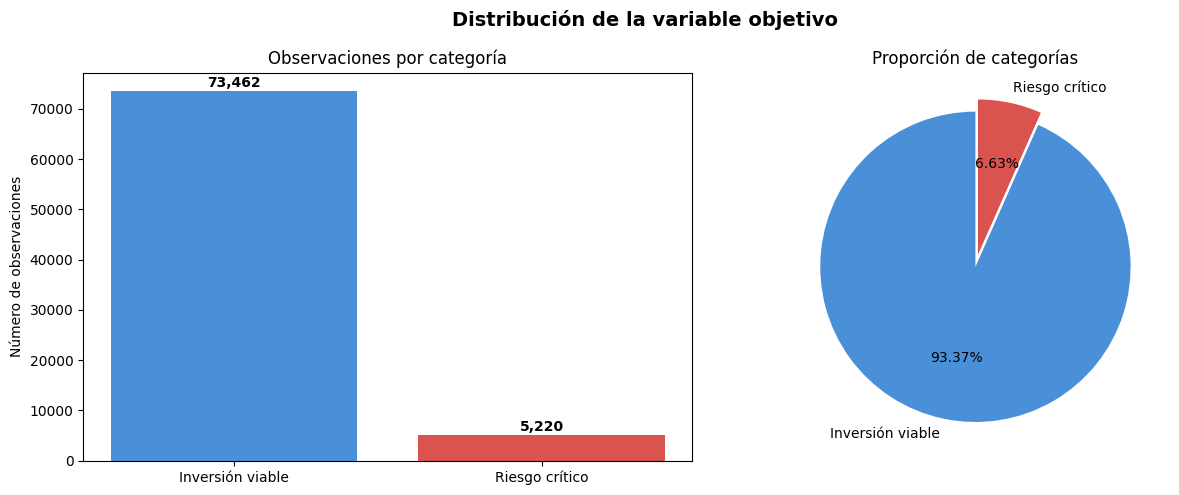

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
etiquetas = ['Inversión viable', 'Riesgo crítico']
colores = ['#4A90D9', '#D9534F']

barras = axes[0].bar(etiquetas, conteo.values, color=colores)
for b, v in zip(barras, conteo.values):
    axes[0].text(b.get_x() + b.get_width() / 2, v + 800, f'{v:,}',
                 ha='center', fontweight='bold')
axes[0].set_ylabel('Número de observaciones')
axes[0].set_title('Observaciones por categoría')

axes[1].pie(conteo.values, labels=etiquetas, colors=colores,
            autopct='%1.2f%%', startangle=90, explode=(0, 0.08))
axes[1].set_title('Proporción de categorías')

fig.suptitle('Distribución de la variable objetivo', fontweight='bold', fontsize=14)
plt.tight_layout()
plt.show()

**Figura 2: distribución por año**

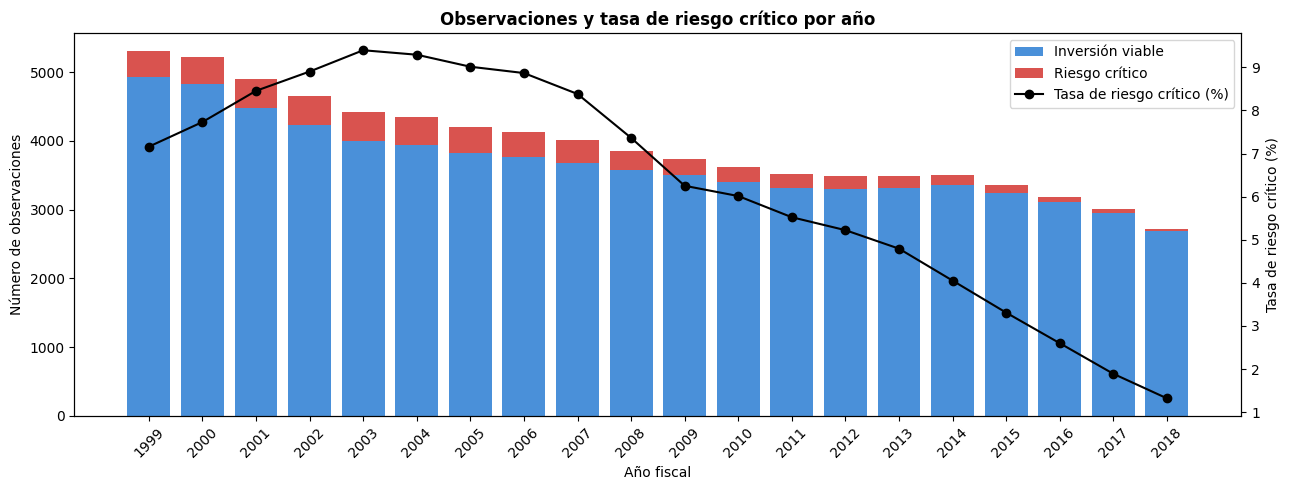

In [ ]:
por_anio = df.groupby('anio')['riesgo_critico'].agg(total='count', riesgo='sum')
por_anio['viable'] = por_anio['total'] - por_anio['riesgo']
por_anio['tasa_riesgo'] = por_anio['riesgo'] / por_anio['total'] * 100

fig, ax1 = plt.subplots(figsize=(13, 5))
ax1.bar(por_anio.index, por_anio['viable'], color='#4A90D9', label='Inversión viable')
ax1.bar(por_anio.index, por_anio['riesgo'], bottom=por_anio['viable'],
        color='#D9534F', label='Riesgo crítico')
ax1.set_xlabel('Año fiscal')
ax1.set_ylabel('Número de observaciones')
ax1.set_xticks(por_anio.index)
ax1.tick_params(axis='x', rotation=45)

ax2 = ax1.twinx()
ax2.plot(por_anio.index, por_anio['tasa_riesgo'], color='black', marker='o',
         label='Tasa de riesgo crítico (%)')
ax2.set_ylabel('Tasa de riesgo crítico (%)')

h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc='upper right')
plt.title('Observaciones y tasa de riesgo crítico por año', fontweight='bold')
plt.tight_layout()
plt.show()

**Elaboración del data-set: indicadores derivados**

In [ ]:
def dividir(numerador, denominador):
    """División segura: si el denominador es 0 devuelve NaN en lugar de infinito."""
    return numerador / denominador.replace(0, np.nan)

df = df.sort_values(['empresa', 'anio']).reset_index(drop=True)

# Liquidez
df['liquidez_corriente'] = dividir(df['activo_corriente'], df['pasivo_corriente'])
df['prueba_acida'] = dividir(df['activo_corriente'] - df['inventario'], df['pasivo_corriente'])
df['capital_trabajo_activos'] = dividir(df['activo_corriente'] - df['pasivo_corriente'], df['activo_total'])

# Solvencia
df['endeudamiento'] = dividir(df['pasivo_total'], df['activo_total'])
df['deuda_lp_activos'] = dividir(df['deuda_largo_plazo'], df['activo_total'])
df['utilidades_retenidas_activos'] = dividir(df['utilidades_retenidas'], df['activo_total'])

# Rentabilidad
df['ebit_activos'] = dividir(df['ebit'], df['activo_total'])
df['roa'] = dividir(df['utilidad_neta'], df['activo_total'])
df['margen_bruto'] = dividir(df['utilidad_bruta'], df['ingresos_totales'])
df['margen_ebitda'] = dividir(df['ebitda'], df['ingresos_totales'])
df['margen_neto'] = dividir(df['utilidad_neta'], df['ingresos_totales'])

# Mercado y eficiencia operativa
df['valor_mercado_pasivos'] = dividir(df['valor_mercado'], df['pasivo_total'])
df['rotacion_activos'] = dividir(df['ventas_netas'], df['activo_total'])
df['gastos_operativos_ingresos'] = dividir(df['gastos_operativos'], df['ingresos_totales'])
df['rotacion_cuentas_cobrar'] = dividir(df['ventas_netas'], df['cuentas_por_cobrar'])

# Crecimiento anual de ingresos por empresa
ingreso_anterior = df.groupby('empresa')['ingresos_totales'].shift(1)
df['crecimiento_ingresos'] = dividir(df['ingresos_totales'] - ingreso_anterior, ingreso_anterior.abs())

VARIABLES_DERIVADAS = [
    'liquidez_corriente', 'prueba_acida', 'capital_trabajo_activos', 'endeudamiento',
    'deuda_lp_activos', 'utilidades_retenidas_activos', 'ebit_activos', 'roa',
    'margen_bruto', 'margen_ebitda', 'margen_neto', 'valor_mercado_pasivos',
    'rotacion_activos', 'gastos_operativos_ingresos', 'rotacion_cuentas_cobrar',
    'crecimiento_ingresos'
]

print("Valores indefinidos generados (se tratarán en 3.2):")
print(df[VARIABLES_DERIVADAS].isna().sum())
print(f"\nData-set elaborado: {df.shape[0]:,} filas x {df.shape[1]} columnas")

Valores indefinidos generados (se tratarán en 3.2):
liquidez_corriente                 0
prueba_acida                       0
capital_trabajo_activos            0
endeudamiento                      0
deuda_lp_activos                   0
utilidades_retenidas_activos       0
ebit_activos                       0
roa                                0
margen_bruto                       0
margen_ebitda                      0
margen_neto                        0
valor_mercado_pasivos              0
rotacion_activos                   0
gastos_operativos_ingresos         0
rotacion_cuentas_cobrar         2205
crecimiento_ingresos            8971
dtype: int64

Data-set elaborado: 78,682 filas x 38 columnas


**Figura 3: indicadores por categoría**


/tmp/ipykernel_1232/2703277172.py:8: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(datos, labels=['Viable', 'Riesgo crítico'],
/tmp/ipykernel_1232/2703277172.py:8: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(datos, labels=['Viable', 'Riesgo crítico'],
/tmp/ipykernel_1232/2703277172.py:8: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(datos, labels=['Viable', 'Riesgo crítico'],
/tmp/ipykernel_1232/2703277172.py:8: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped

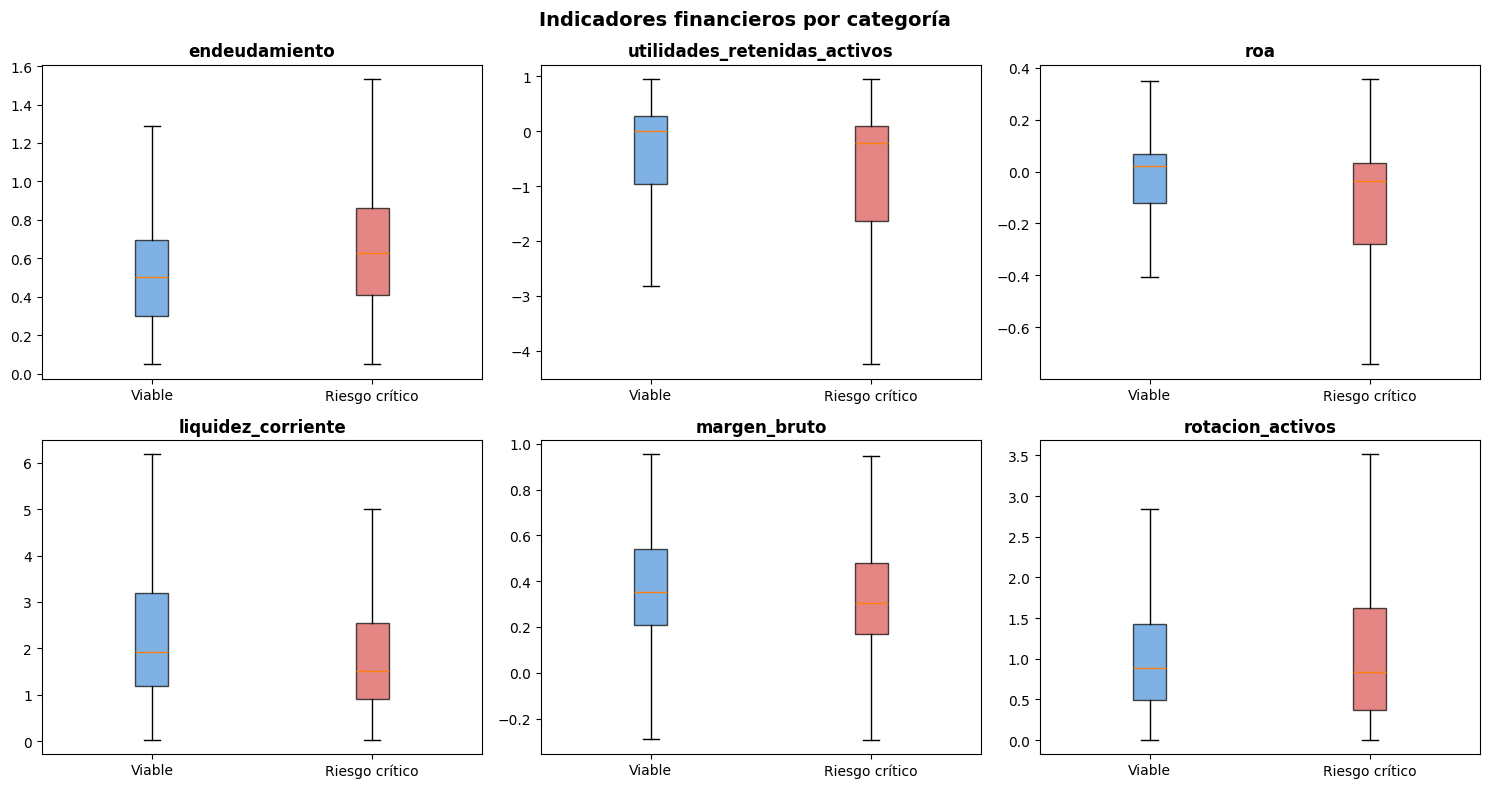

In [ ]:
indicadores_graf = ['endeudamiento', 'utilidades_retenidas_activos', 'roa',
                    'liquidez_corriente', 'margen_bruto', 'rotacion_activos']

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, var in zip(axes.flatten(), indicadores_graf):
    li, ls = df[var].quantile([0.01, 0.99])  # recorte solo para visualizar
    datos = [df.loc[(df['riesgo_critico'] == c) & df[var].between(li, ls), var] for c in (0, 1)]
    bp = ax.boxplot(datos, labels=['Viable', 'Riesgo crítico'],
                    showfliers=False, patch_artist=True)
    for caja, color in zip(bp['boxes'], ['#4A90D9', '#D9534F']):
        caja.set_facecolor(color)
        caja.set_alpha(0.7)
    ax.set_title(var, fontweight='bold')

fig.suptitle('Indicadores financieros por categoría', fontweight='bold', fontsize=14)
plt.tight_layout()
plt.show()

**Guardado en Google Drive**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

RUTA_PROYECTO = '/content/drive/MyDrive/PROYECTO_IA'
os.makedirs(RUTA_PROYECTO, exist_ok=True)

columnas_finales = ['empresa', 'anio'] + VARIABLES_ORIGINALES + VARIABLES_DERIVADAS + ['riesgo_critico']
df[columnas_finales].to_csv(f'{RUTA_PROYECTO}/dataset_elaborado.csv', index=False)
print(f"Guardado: {RUTA_PROYECTO}/dataset_elaborado.csv")

Mounted at /content/drive
Guardado: /content/drive/MyDrive/PROYECTO_IA/dataset_elaborado.csv


**Filtrado y selección de variables (Tabla 4)**

In [ ]:
df = pd.read_csv('/content/drive/MyDrive/PROYECTO_IA/dataset_elaborado.csv')

# Valores infinitos -> faltantes
df = df.replace([np.inf, -np.inf], np.nan)

# Tamaño de la empresa en escala logarítmica
df['tamano_empresa'] = np.log1p(df['activo_total'].clip(lower=0))

VARIABLES_MODELO = [
    'liquidez_corriente', 'prueba_acida', 'capital_trabajo_activos', 'endeudamiento',
    'deuda_lp_activos', 'utilidades_retenidas_activos', 'ebit_activos', 'roa',
    'margen_bruto', 'margen_ebitda', 'margen_neto', 'valor_mercado_pasivos',
    'rotacion_activos', 'gastos_operativos_ingresos', 'rotacion_cuentas_cobrar',
    'crecimiento_ingresos', 'tamano_empresa'
]

def pct_atipicos(s):
    s = s.dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).mean() * 100

tabla_calidad = pd.DataFrame({
    'Faltantes (%)': df[VARIABLES_MODELO].isna().mean() * 100,
    'Atípicos IQR (%)': df[VARIABLES_MODELO].apply(pct_atipicos)
}).round(2)
display(tabla_calidad)

,Faltantes (%),Atípicos IQR (%)
liquidez_corriente,0.0,8.50
prueba_acida,0.0,9.51
capital_trabajo_activos,0.0,4.92
endeudamiento,0.0,6.29
deuda_lp_activos,0.0,3.58
utilidades_retenidas_activos,0.0,14.29
ebit_activos,0.0,13.28
roa,0.0,13.95
margen_bruto,0.0,6.76
margen_ebitda,0.0,18.28


**Definición del preprocesador**


In [ ]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler

class Winsorizador(BaseEstimator, TransformerMixin):
    """Recorta cada variable a sus percentiles inferior y superior."""
    def __init__(self, inferior=0.01, superior=0.99):
        self.inferior = inferior
        self.superior = superior

    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        self.lim_inf_ = np.nanquantile(X, self.inferior, axis=0)
        self.lim_sup_ = np.nanquantile(X, self.superior, axis=0)
        return self

    def transform(self, X):
        return np.clip(np.asarray(X, dtype=float), self.lim_inf_, self.lim_sup_)

preprocesador = Pipeline([
    ('imputacion', SimpleImputer(strategy='median')),
    ('winsorizacion', Winsorizador(0.01, 0.99)),
    ('escalado', RobustScaler())
])
print(preprocesador)

Pipeline(steps=[('imputacion', SimpleImputer(strategy='median')),
                ('winsorizacion', Winsorizador()),
                ('escalado', RobustScaler())])


**Figura 4: efecto del preprocesamiento**

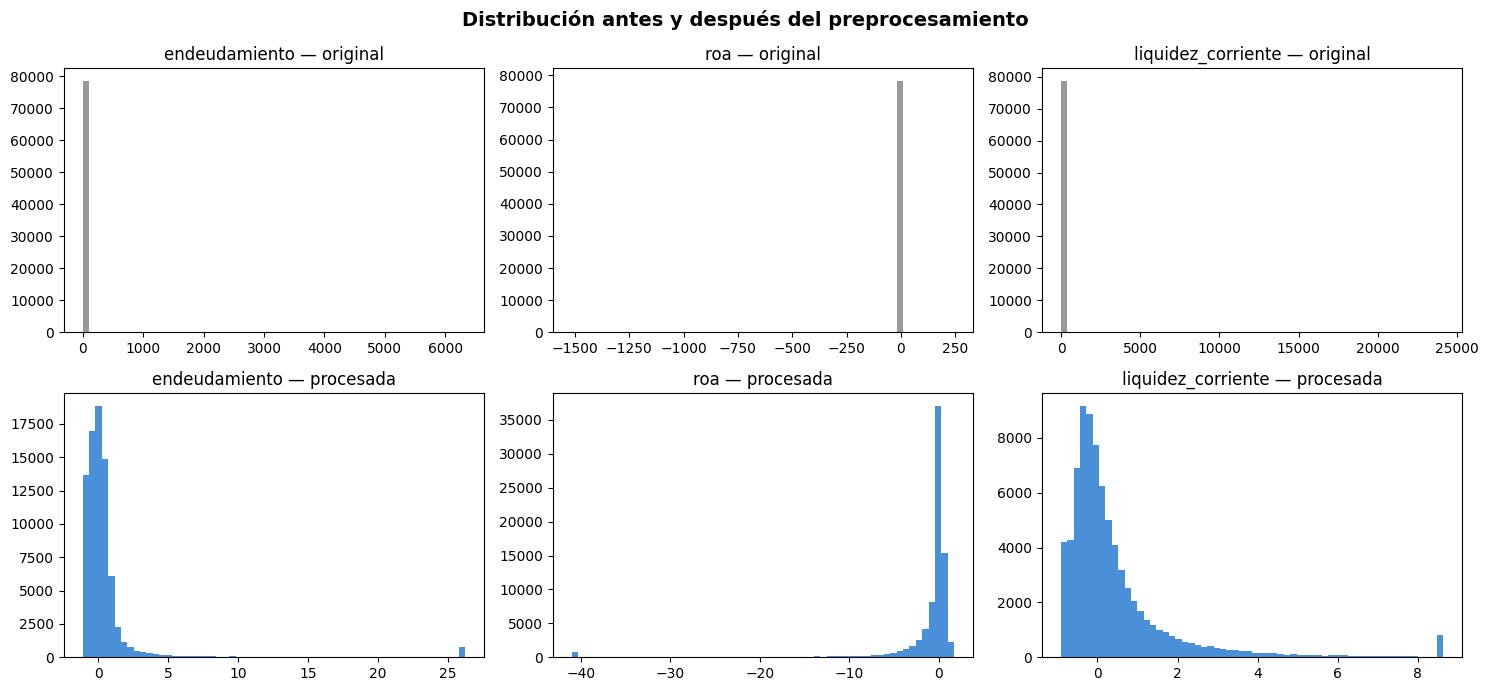

In [ ]:
from sklearn.base import clone

# Ajuste sobre todo el dataset SOLO para ilustrar; en 3.3 se ajusta con entrenamiento
X_ilustr = pd.DataFrame(clone(preprocesador).fit_transform(df[VARIABLES_MODELO]),
                        columns=VARIABLES_MODELO)

vars_graf = ['endeudamiento', 'roa', 'liquidez_corriente']
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for i, v in enumerate(vars_graf):
    axes[0, i].hist(df[v].dropna(), bins=60, color='#999999')
    axes[0, i].set_title(f'{v} — original')
    axes[1, i].hist(X_ilustr[v], bins=60, color='#4A90D9')
    axes[1, i].set_title(f'{v} — procesada')

fig.suptitle('Distribución antes y después del preprocesamiento', fontweight='bold', fontsize=14)
plt.tight_layout()
plt.show()

**Guardado del data-set filtrado**

In [ ]:
columnas = ['empresa', 'anio'] + VARIABLES_MODELO + ['riesgo_critico']
df[columnas].to_csv(f'{RUTA_PROYECTO}/dataset_filtrado.csv', index=False)
print(f"Guardado: {RUTA_PROYECTO}/dataset_filtrado.csv | {df.shape[0]:,} filas x {len(VARIABLES_MODELO)} variables")

Guardado: /content/drive/MyDrive/PROYECTO_IA/dataset_filtrado.csv | 78,682 filas x 17 variables


**Particion por empresa**

In [ ]:
from sklearn.model_selection import StratifiedGroupKFold

X = df[VARIABLES_MODELO].copy()
y = df['riesgo_critico'].copy()
grupos = df['empresa'].copy()

# RF04: partición estratificada por empresa -> 4 grupos entrenamiento (80 %), 1 grupo prueba (20 %)
particion = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
idx_train, idx_test = next(particion.split(X, y, groups=grupos))

X_train, X_test = X.iloc[idx_train], X.iloc[idx_test]
y_train, y_test = y.iloc[idx_train], y.iloc[idx_test]
g_train, g_test = grupos.iloc[idx_train], grupos.iloc[idx_test]

# Control de fuga: ninguna empresa debe aparecer en ambos conjuntos
print("Empresas compartidas entre entrenamiento y prueba:", len(set(g_train) & set(g_test)))

Empresas compartidas entre entrenamiento y prueba: 0


**Composicion de la partición (Tabla 5)**

In [ ]:
def resumen_conjunto(nombre, y_, g_):
    return {
        'Conjunto': nombre,
        'Empresas': g_.nunique(),
        'Empresas en riesgo': g_[y_ == 1].nunique(),
        'Observaciones': len(y_),
        'Viable (0)': int((y_ == 0).sum()),
        'Riesgo crítico (1)': int((y_ == 1).sum()),
        'Riesgo crítico (%)': round(y_.mean() * 100, 2),
        'Participación (%)': round(len(y_) / len(y) * 100, 2)
    }

tabla_particion = pd.DataFrame([
    resumen_conjunto('Entrenamiento', y_train, g_train),
    resumen_conjunto('Prueba', y_test, g_test),
    resumen_conjunto('Total', y, grupos)
])
display(tabla_particion)

,Conjunto,Empresas,Empresas en riesgo,Observaciones,Viable (0),Riesgo crítico (1),Riesgo crítico (%),Participación (%)
0,Entrenamiento,7177,485,62940,58769,4171,6.63,79.99
1,Prueba,1794,124,15742,14693,1049,6.66,20.01
2,Total,8971,609,78682,73462,5220,6.63,100.00


**Comparación entre subconjuntos (Figura 5)**

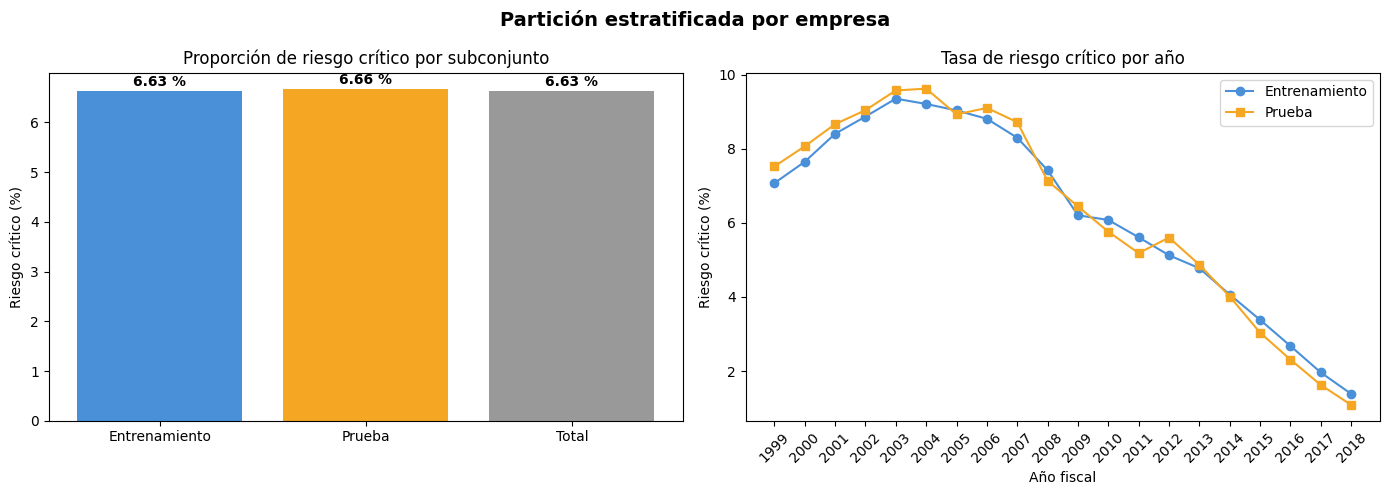

In [ ]:
anios = df['anio']
tasa_train = y_train.groupby(anios.iloc[idx_train]).mean() * 100
tasa_test = y_test.groupby(anios.iloc[idx_test]).mean() * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

conjuntos = ['Entrenamiento', 'Prueba', 'Total']
tasas = [y_train.mean() * 100, y_test.mean() * 100, y.mean() * 100]
barras = axes[0].bar(conjuntos, tasas, color=['#4A90D9', '#F5A623', '#999999'])
for b, v in zip(barras, tasas):
    axes[0].text(b.get_x() + b.get_width() / 2, v + 0.1, f'{v:.2f} %', ha='center', fontweight='bold')
axes[0].set_ylabel('Riesgo crítico (%)')
axes[0].set_title('Proporción de riesgo crítico por subconjunto')

axes[1].plot(tasa_train.index, tasa_train.values, marker='o', color='#4A90D9', label='Entrenamiento')
axes[1].plot(tasa_test.index, tasa_test.values, marker='s', color='#F5A623', label='Prueba')
axes[1].set_xlabel('Año fiscal')
axes[1].set_ylabel('Riesgo crítico (%)')
axes[1].set_xticks(tasa_train.index)
axes[1].tick_params(axis='x', rotation=45)
axes[1].set_title('Tasa de riesgo crítico por año')
axes[1].legend()

fig.suptitle('Partición estratificada por empresa', fontweight='bold', fontsize=14)
plt.tight_layout()
plt.show()

**Persistencia de la partición**

In [ ]:
df.iloc[idx_train].to_csv(f'{RUTA_PROYECTO}/dataset_entrenamiento.csv', index=False)
df.iloc[idx_test].to_csv(f'{RUTA_PROYECTO}/dataset_prueba.csv', index=False)
print(f"Guardado: {RUTA_PROYECTO}/dataset_entrenamiento.csv  ->  {len(idx_train):,} filas")
print(f"Guardado: {RUTA_PROYECTO}/dataset_prueba.csv  ->  {len(idx_test):,} filas")

Guardado: /content/drive/MyDrive/PROYECTO_IA/dataset_entrenamiento.csv  ->  62,940 filas
Guardado: /content/drive/MyDrive/PROYECTO_IA/dataset_prueba.csv  ->  15,742 filas


**Esquema de Validacion y Pipeline Reutilizable**

In [ ]:
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from sklearn.base import clone

cv_interna = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEMILLA)

def crear_pipeline(modelo):
    """Preprocesamiento + SMOTE + clasificador; se reajusta dentro de cada pliegue."""
    # Desempaquetamos los pasos individuales del preprocesador para evitar pipelines anidados
    return ImbPipeline([
        ('imputacion', clone(preprocesador.named_steps['imputacion'])),
        ('winsorizacion', clone(preprocesador.named_steps['winsorizacion'])),
        ('escalado', clone(preprocesador.named_steps['escalado'])),
        ('smote', SMOTE(random_state=SEMILLA)),
        ('modelo', modelo)
    ])

METRICAS_CV = {
    'recall_riesgo': 'recall',
    'precision_riesgo': 'precision',
    'f1_riesgo': 'f1',
    'pr_auc': 'average_precision',
    'exactitud': 'accuracy'
}

**Composición de los pliegues (Tabla 6)**

In [ ]:
filas = []
for k, (i_aj, i_val) in enumerate(cv_interna.split(X_train, y_train, groups=g_train), start=1):
    y_aj, y_val = y_train.iloc[i_aj], y_train.iloc[i_val]
    g_aj, g_val = g_train.iloc[i_aj], g_train.iloc[i_val]

    X_aj_prep = clone(preprocesador).fit_transform(X_train.iloc[i_aj])
    _, y_aj_smote = SMOTE(random_state=SEMILLA).fit_resample(X_aj_prep, y_aj)

    if k == 1:  # se guarda para la Figura 6
        antes_smote = y_aj.value_counts().sort_index()
        despues_smote = pd.Series(y_aj_smote).value_counts().sort_index()

    filas.append({
        'Pliegue': k,
        'Empresas ajuste': g_aj.nunique(),
        'Empresas validación': g_val.nunique(),
        'Empresas compartidas': len(set(g_aj) & set(g_val)),
        'Obs. ajuste': len(y_aj),
        'Obs. validación': len(y_val),
        'Riesgo ajuste (%)': round(y_aj.mean() * 100, 2),
        'Riesgo validación (%)': round(y_val.mean() * 100, 2),
        'Obs. ajuste tras SMOTE': len(y_aj_smote)
    })

tabla_pliegues = pd.DataFrame(filas)
display(tabla_pliegues)

,Pliegue,Empresas ajuste,Empresas validación,Empresas compartidas,Obs. ajuste,Obs. validación,Riesgo ajuste (%),Riesgo validación (%),Obs. ajuste tras SMOTE
0,1,5742,1435,0,50706,12234,6.85,5.70,94464
1,2,5742,1435,0,50314,12626,6.58,6.80,94004
2,3,5742,1435,0,50381,12559,6.28,8.03,94436
3,4,5741,1436,0,50419,12521,6.80,5.92,93978
4,5,5741,1436,0,49940,13000,6.62,6.66,93270


**Efecto de SMOTE en el pliegue 1 (Figura 6)**

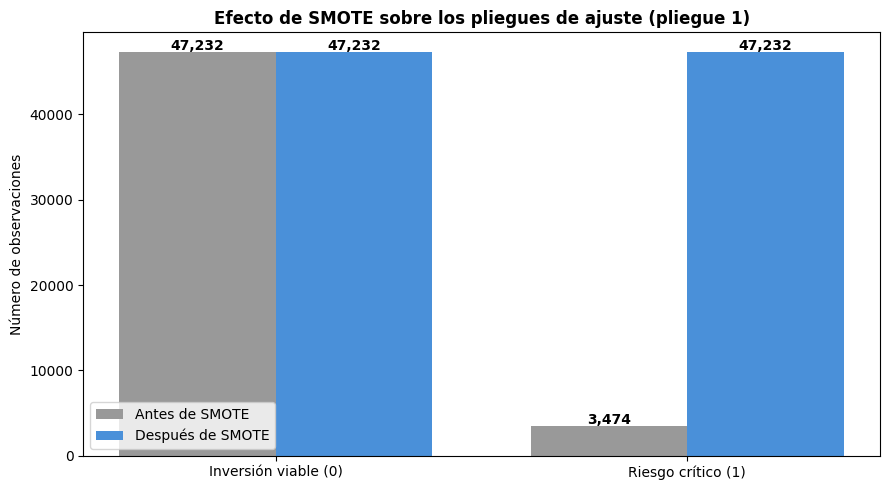

In [ ]:
fig, ax = plt.subplots(figsize=(9, 5))
etiquetas = ['Inversión viable (0)', 'Riesgo crítico (1)']
x = np.arange(len(etiquetas))
ancho = 0.38

b1 = ax.bar(x - ancho / 2, antes_smote.values, ancho, color='#999999', label='Antes de SMOTE')
b2 = ax.bar(x + ancho / 2, despues_smote.values, ancho, color='#4A90D9', label='Después de SMOTE')
for barras in (b1, b2):
    for b in barras:
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 300,
                f'{int(b.get_height()):,}', ha='center', fontweight='bold')

ax.set_xticks(x)
ax.set_xticklabels(etiquetas)
ax.set_ylabel('Número de observaciones')
ax.set_title('Efecto de SMOTE sobre los pliegues de ajuste (pliegue 1)', fontweight='bold')
ax.legend()
plt.tight_layout()
plt.show()

**Definicion de Modelos y Tabla 6**

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

MODELOS = {
    'Regresión logística': LogisticRegression(max_iter=2000, random_state=SEMILLA),
    'Random Forest': RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                                            n_jobs=-1, random_state=SEMILLA),
    'Gradient Boosting': HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05,
                                                        early_stopping=False,
                                                        random_state=SEMILLA)
}

tabla_hiper = pd.DataFrame([
    ['Regresión logística', 'C', '1.0', 'Inverso de la fuerza de regularización'],
    ['Regresión logística', 'max_iter', '2000', 'Iteraciones máximas del optimizador'],
    ['Random Forest', 'n_estimators', '300', 'Número de árboles del bosque'],
    ['Random Forest', 'min_samples_leaf', '5', 'Observaciones mínimas por hoja'],
    ['Random Forest', 'max_features', 'sqrt', 'Variables evaluadas en cada división'],
    ['Gradient Boosting', 'max_iter', '300', 'Número de árboles secuenciales'],
    ['Gradient Boosting', 'learning_rate', '0.05', 'Peso de cada árbol en la corrección'],
    ['Gradient Boosting', 'early_stopping', 'False', 'Detención temprana desactivada'],
    ['Todos', 'random_state', '42', 'Semilla de reproducibilidad (RNF05)'],
], columns=['Algoritmo', 'Hiperparámetro', 'Valor inicial', 'Descripción'])
display(tabla_hiper)

,Algoritmo,Hiperparámetro,Valor inicial,Descripción
0,Regresión logística,C,1.0,Inverso de la fuerza de regularización
1,Regresión logística,max_iter,2000,Iteraciones máximas del optimizador
2,Random Forest,n_estimators,300,Número de árboles del bosque
3,Random Forest,min_samples_leaf,5,Observaciones mínimas por hoja
4,Random Forest,max_features,sqrt,Variables evaluadas en cada división
5,Gradient Boosting,max_iter,300,Número de árboles secuenciales
6,Gradient Boosting,learning_rate,0.05,Peso de cada árbol en la corrección
7,Gradient Boosting,early_stopping,False,Detención temprana desactivada
8,Todos,random_state,42,Semilla de reproducibilidad (RNF05)


**Comparacion y Tabla 7**

In [ ]:
from sklearn.model_selection import cross_validate
import time

resultados_cv = {}
filas = []
for nombre, modelo in MODELOS.items():
    inicio = time.time()
    cv = cross_validate(crear_pipeline(modelo), X_train, y_train, groups=g_train,
                        cv=cv_interna, scoring=METRICAS_CV,
                        return_train_score=True, n_jobs=1)
    duracion = time.time() - inicio
    resultados_cv[nombre] = cv

    fila = {'Algoritmo': nombre}
    for m in METRICAS_CV:
        fila[m] = f"{cv[f'test_{m}'].mean():.3f} ± {cv[f'test_{m}'].std():.3f}"
    fila['f1_riesgo (ajuste)'] = f"{cv['train_f1_riesgo'].mean():.3f}"
    fila['Tiempo (s)'] = round(duracion)
    filas.append(fila)
    print(f'{nombre}: completado en {duracion:.0f} s')

tabla_comparacion = pd.DataFrame(filas).set_index('Algoritmo')
display(tabla_comparacion)

Regresión logística: completado en 30 s
Random Forest: completado en 671 s
Gradient Boosting: completado en 35 s


,recall_riesgo,precision_riesgo,f1_riesgo,pr_auc,exactitud,f1_riesgo (ajuste),Tiempo (s)
Algoritmo,,,,,,,
Regresión logística,0.539 ± 0.043,0.099 ± 0.013,0.167 ± 0.020,0.102 ± 0.014,0.645 ± 0.017,0.174,30
Random Forest,0.252 ± 0.036,0.178 ± 0.039,0.208 ± 0.038,0.140 ± 0.027,0.873 ± 0.010,0.917,671
Gradient Boosting,0.423 ± 0.047,0.132 ± 0.022,0.201 ± 0.030,0.137 ± 0.027,0.777 ± 0.014,0.371,35


**Figura 7**

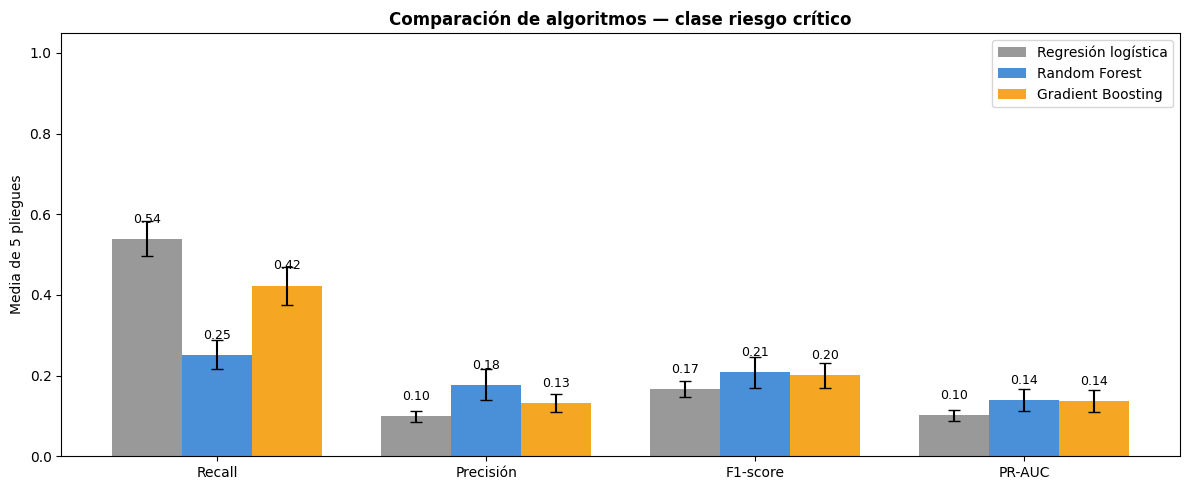

In [ ]:
metricas_graf = ['recall_riesgo', 'precision_riesgo', 'f1_riesgo', 'pr_auc']
etiquetas_m = ['Recall', 'Precisión', 'F1-score', 'PR-AUC']
nombres = list(MODELOS)
colores = ['#999999', '#4A90D9', '#F5A623']
x = np.arange(len(metricas_graf))
ancho = 0.26

fig, ax = plt.subplots(figsize=(12, 5))
for i, nombre in enumerate(nombres):
    medias = [resultados_cv[nombre][f'test_{m}'].mean() for m in metricas_graf]
    desv = [resultados_cv[nombre][f'test_{m}'].std() for m in metricas_graf]
    barras = ax.bar(x + (i - 1) * ancho, medias, ancho, yerr=desv, capsize=4,
                    color=colores[i], label=nombre)
    for b, v in zip(barras, medias):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.04, f'{v:.2f}', ha='center', fontsize=9)

ax.set_xticks(x)
ax.set_xticklabels(etiquetas_m)
ax.set_ylim(0, 1.05)
ax.set_ylabel('Media de 5 pliegues')
ax.set_title('Comparación de algoritmos — clase riesgo crítico', fontweight='bold')
ax.legend()
plt.tight_layout()
plt.show()

**Seleccion del algoritmo**

In [ ]:
media_f1 = {n: resultados_cv[n]['test_f1_riesgo'].mean() for n in MODELOS}
media_rec = {n: resultados_cv[n]['test_recall_riesgo'].mean() for n in MODELOS}

# Criterio 4.1.4: mayor F1 de riesgo crítico; en empate a 3 decimales, mayor recall
MODELO_ELEGIDO = max(MODELOS, key=lambda n: (round(media_f1[n], 3), media_rec[n]))
print('Modelo seleccionado:', MODELO_ELEGIDO)

Modelo seleccionado: Random Forest


**Busqueda de Hiperparametros**

In [ ]:
from sklearn.model_selection import GridSearchCV
import joblib, json

print('CPUs disponibles:', os.cpu_count())

# Versión ligera del bosque, solo para comparar configuraciones
rf_busqueda = RandomForestClassifier(
    n_estimators=100, max_samples=0.5, max_features='sqrt',
    min_samples_leaf=5, n_jobs=-1, random_state=SEMILLA
)

rejilla = {
    'smote__sampling_strategy': [0.5, 0.75, 1.0],
    'modelo__min_samples_leaf': [5, 20],
}

busqueda = GridSearchCV(
    crear_pipeline(rf_busqueda),
    param_grid=rejilla,
    scoring=METRICAS_CV,
    refit=False,      # el modelo final se entrena aparte, en la celda 14
    cv=cv_interna,
    n_jobs=1,
    verbose=2         # imprime el tiempo de cada entrenamiento
)

t0 = time.time()
busqueda.fit(X_train, y_train, groups=g_train)
print(f'Búsqueda completada en {(time.time() - t0) / 60:.1f} min')

joblib.dump(busqueda.cv_results_, f'{RUTA_PROYECTO}/resultados_busqueda.joblib')
print('Resultados guardados en Drive')

CPUs disponibles: 2
Fitting 5 folds for each of 6 candidates, totalling 30 fits
[CV] END modelo__min_samples_leaf=5, smote__sampling_strategy=0.5; total time=  17.5s
[CV] END modelo__min_samples_leaf=5, smote__sampling_strategy=0.5; total time=  16.6s
[CV] END modelo__min_samples_leaf=5, smote__sampling_strategy=0.5; total time=  18.1s
[CV] END modelo__min_samples_leaf=5, smote__sampling_strategy=0.5; total time=  16.8s
[CV] END modelo__min_samples_leaf=5, smote__sampling_strategy=0.5; total time=  17.7s
[CV] END modelo__min_samples_leaf=5, smote__sampling_strategy=0.75; total time=  20.4s
[CV] END modelo__min_samples_leaf=5, smote__sampling_strategy=0.75; total time=  21.5s
[CV] END modelo__min_samples_leaf=5, smote__sampling_strategy=0.75; total time=  21.3s
[CV] END modelo__min_samples_leaf=5, smote__sampling_strategy=0.75; total time=  20.5s
[CV] END modelo__min_samples_leaf=5, smote__sampling_strategy=0.75; total time=  21.2s
[CV] END modelo__min_samples_leaf=5, smote__sampling_st

**Configuracion inicial vs Ajustada (Tabla 8)**

In [ ]:
res = pd.DataFrame(busqueda.cv_results_).sort_values('rank_test_f1_riesgo')

def mas_menos(col):
    return (res[f'mean_test_{col}'].round(3).astype(str) + ' ± ' +
            res[f'std_test_{col}'].round(3).astype(str)).values

tabla_ajuste = pd.DataFrame({
    'SMOTE (proporción)': res['param_smote__sampling_strategy'].values,
    'Observaciones por hoja': res['param_modelo__min_samples_leaf'].values,
    'F1 (riesgo)': mas_menos('f1_riesgo'),
    'Recall (riesgo)': mas_menos('recall_riesgo'),
    'Precisión (riesgo)': mas_menos('precision_riesgo'),
    'PR-AUC': mas_menos('pr_auc'),
    'Tiempo por ajuste (s)': res['mean_fit_time'].round(0).values
})
display(tabla_ajuste.reset_index(drop=True))

MEJORES = res.iloc[0]['params']
print('Mejor configuración:', MEJORES)

,SMOTE (proporción),Observaciones por hoja,F1 (riesgo),Recall (riesgo),Precisión (riesgo),PR-AUC,Tiempo por ajuste (s)
0,1.00,20,0.221 ± 0.033,0.415 ± 0.046,0.151 ± 0.026,0.146 ± 0.026,23.0
1,0.75,20,0.221 ± 0.036,0.339 ± 0.043,0.164 ± 0.031,0.147 ± 0.026,19.0
2,1.00,5,0.213 ± 0.04,0.304 ± 0.045,0.165 ± 0.036,0.141 ± 0.027,25.0
3,0.50,20,0.21 ± 0.035,0.232 ± 0.037,0.192 ± 0.035,0.151 ± 0.025,15.0
4,0.75,5,0.209 ± 0.037,0.255 ± 0.037,0.178 ± 0.038,0.143 ± 0.026,21.0
5,0.50,5,0.184 ± 0.034,0.174 ± 0.029,0.195 ± 0.042,0.145 ± 0.027,17.0


Mejor configuración: {'modelo__min_samples_leaf': 20, 'smote__sampling_strategy': 1.0}


**Captura del modelo, guardado y RNF03**

In [ ]:
from sklearn import set_config

rf_final = RandomForestClassifier(
    n_estimators=300, max_samples=0.5, max_features='sqrt',
    min_samples_leaf=MEJORES['modelo__min_samples_leaf'],
    n_jobs=-1, random_state=SEMILLA
)
modelo_final = crear_pipeline(rf_final)
modelo_final.set_params(smote__sampling_strategy=MEJORES['smote__sampling_strategy'])

t0 = time.time()
modelo_final.fit(X_train, y_train)
print(f'Entrenamiento final: {(time.time() - t0) / 60:.1f} min')

set_config(display='diagram')
display(modelo_final)   # <- Figura 8: captura del modelo elegido

# RF11: persistencia
ruta_modelo = f'{RUTA_PROYECTO}/modelo_final.joblib'
joblib.dump(modelo_final, ruta_modelo, compress=3)

mejor = res.iloc[0]
metadatos = {
    'algoritmo': 'Random Forest',
    'hiperparametros': {'n_estimators': 300, 'max_samples': 0.5, 'max_features': 'sqrt',
                        'min_samples_leaf': int(MEJORES['modelo__min_samples_leaf']),
                        'smote_sampling_strategy': float(MEJORES['smote__sampling_strategy'])},
    'variables': VARIABLES_MODELO,
    'semilla': SEMILLA,
    'f1_riesgo_cv_busqueda': round(float(mejor['mean_test_f1_riesgo']), 4),
    'recall_riesgo_cv_busqueda': round(float(mejor['mean_test_recall_riesgo']), 4)
}
with open(f'{RUTA_PROYECTO}/modelo_final_metadatos.json', 'w', encoding='utf-8') as f:
    json.dump(metadatos, f, ensure_ascii=False, indent=2)
print('Guardado:', ruta_modelo)

# RNF03: tiempo de clasificar una empresa con el modelo recuperado
modelo_cargado = joblib.load(ruta_modelo)
t0 = time.perf_counter()
modelo_cargado.predict(X_train.iloc[[0]])
print(f'Tiempo de clasificación de una empresa: {time.perf_counter() - t0:.4f} s')

Entrenamiento final: 1.5 min


Pipeline(steps=[('imputacion', SimpleImputer(strategy='median')),
                ('winsorizacion', Winsorizador()), ('escalado', RobustScaler()),
                ('smote', SMOTE(random_state=42, sampling_strategy=1.0)),
                ('modelo',
                 RandomForestClassifier(max_samples=0.5, min_samples_leaf=20,
                                        n_estimators=300, n_jobs=-1,
                                        random_state=42))])

Guardado: /content/drive/MyDrive/PROYECTO_IA/modelo_final.joblib
Tiempo de clasificación de una empresa: 0.0567 s


In [ ]:
from sklearn.model_selection import cross_validate

cv_final = cross_validate(modelo_final, X_train, y_train, groups=g_train, cv=cv_interna,
                          scoring=METRICAS_CV, return_train_score=True, n_jobs=1)
print('F1 ajuste     :', round(cv_final['train_f1_riesgo'].mean(), 3))
print('F1 validación :', round(cv_final['test_f1_riesgo'].mean(), 3), '±', round(cv_final['test_f1_riesgo'].std(), 3))
print('Recall valid. :', round(cv_final['test_recall_riesgo'].mean(), 3))

F1 ajuste     : 0.475
F1 validación : 0.221 ± 0.035
Recall valid. : 0.412


In [ ]:
for a, b in [('Random Forest', 'Gradient Boosting'), ('Random Forest', 'Regresión logística')]:
    d = resultados_cv[a]['test_f1_riesgo'] - resultados_cv[b]['test_f1_riesgo']
    print(f'{a} − {b}: diferencia media {d.mean():+.3f}, gana en {(d > 0).sum()} de 5 pliegues')

Random Forest − Gradient Boosting: diferencia media +0.007, gana en 4 de 5 pliegues
Random Forest − Regresión logística: diferencia media +0.041, gana en 4 de 5 pliegues


In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv_filas = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)

cv_por_filas = cross_validate(modelo_final, X_train, y_train, cv=cv_filas,
                              scoring=METRICAS_CV, n_jobs=1)

print('--- Partición por FILAS (con fuga) ---')
print('F1 validación     :', round(cv_por_filas['test_f1_riesgo'].mean(), 3), '±', round(cv_por_filas['test_f1_riesgo'].std(), 3))
print('Recall validación :', round(cv_por_filas['test_recall_riesgo'].mean(), 3))
print('PR-AUC            :', round(cv_por_filas['test_pr_auc'].mean(), 3))
print()
print('--- Partición por EMPRESA (honesta, resultado de la Celda A) ---')
print('F1 validación     : 0.221 ± 0.035')
print('Recall validación : 0.412')

--- Partición por FILAS (con fuga) ---
F1 validación     : 0.294 ± 0.006
Recall validación : 0.566
PR-AUC            : 0.257

--- Partición por EMPRESA (honesta, resultado de la Celda A) ---
F1 validación     : 0.221 ± 0.035
Recall validación : 0.412


In [ ]:
from sklearn.model_selection import cross_val_predict

# Si la sesión se reinició y 'train' no existe:
train = pd.read_csv(f'{RUTA_PROYECTO}/dataset_entrenamiento.csv')

# Predicciones "fuera de pliegue": cada observación se predice con un modelo que no la vio
pred = cross_val_predict(modelo_final, X_train, y_train, groups=g_train,
                         cv=cv_interna, n_jobs=1)

diag = pd.DataFrame({'empresa': g_train.values,
                     'anio': train['anio'].values,
                     'y': y_train.values,
                     'pred': pred})

# Años que faltan para el último registro de cada empresa
diag['anios_a_quiebra'] = diag.groupby('empresa')['anio'].transform('max') - diag['anio']

riesgo = diag[diag['y'] == 1].copy()
riesgo['tramo'] = pd.cut(riesgo['anios_a_quiebra'],
                         bins=[-1, 0, 1, 2, 4, 100],
                         labels=['0 (último año)', '1', '2', '3-4', '5 o más'])

tabla_tramos = riesgo.groupby('tramo', observed=True).agg(
    observaciones=('pred', 'size'),
    recall=('pred', 'mean')
).round(3)
display(tabla_tramos)

# Referencia: porcentaje de observaciones viables que el modelo marca como riesgo
print('Falsas alarmas en viables:', round(diag[diag['y'] == 0]['pred'].mean(), 3))

,observaciones,recall
tramo,,
0 (último año),485,0.584
1,478,0.546
2,457,0.464
3-4,813,0.424
5 o más,1938,0.326


Falsas alarmas en viables: 0.164


**Curva de Aprendizaje y Figura 9**

Curva de aprendizaje: 14.4 min


,Observaciones de ajuste,F1 ajuste,F1 validación,Desv. validación
0,12676,0.429,0.210,0.029
1,25353,0.447,0.218,0.032
2,38029,0.460,0.216,0.034
3,50706,0.473,0.220,0.036


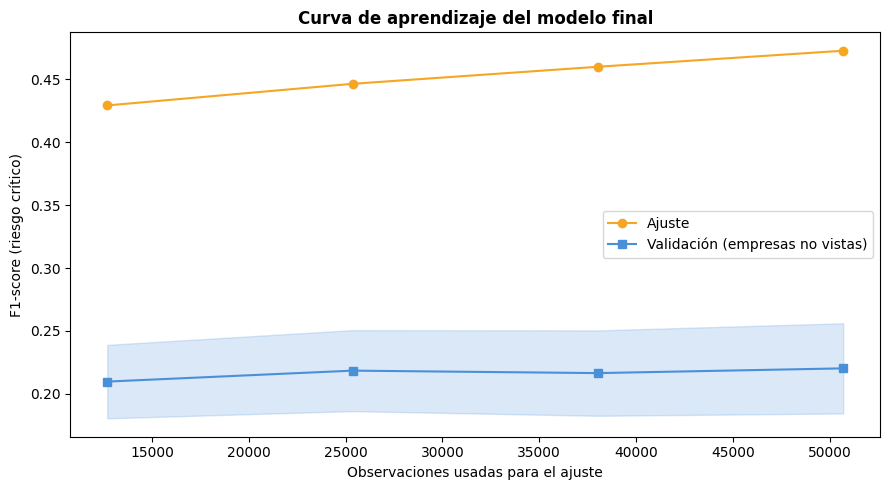

In [ ]:
from sklearn.model_selection import learning_curve
import time

t0 = time.time()
tam, sc_train, sc_val = learning_curve(
    modelo_final, X_train, y_train, groups=g_train, cv=cv_interna,
    train_sizes=[0.25, 0.50, 0.75, 1.0], scoring='f1',
    shuffle=True, random_state=SEMILLA, n_jobs=1
)
print(f'Curva de aprendizaje: {(time.time() - t0) / 60:.1f} min')

tabla_curva = pd.DataFrame({
    'Observaciones de ajuste': tam,
    'F1 ajuste': sc_train.mean(axis=1).round(3),
    'F1 validación': sc_val.mean(axis=1).round(3),
    'Desv. validación': sc_val.std(axis=1).round(3)
})
display(tabla_curva)

m_val, s_val = sc_val.mean(axis=1), sc_val.std(axis=1)
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(tam, sc_train.mean(axis=1), marker='o', color='#F5A623', label='Ajuste')
ax.plot(tam, m_val, marker='s', color='#4A90D9', label='Validación (empresas no vistas)')
ax.fill_between(tam, m_val - s_val, m_val + s_val, color='#4A90D9', alpha=0.2)
ax.set_xlabel('Observaciones usadas para el ajuste')
ax.set_ylabel('F1-score (riesgo crítico)')
ax.set_title('Curva de aprendizaje del modelo final', fontweight='bold')
ax.legend()
plt.tight_layout()
plt.show()

**Por filas frente a por empresa (Tabla 9)**

In [ ]:
def resumen(cv, nombre):
    fila = {'Esquema de partición': nombre}
    for etiqueta, clave in [('F1 (riesgo)', 'f1_riesgo'), ('Recall (riesgo)', 'recall_riesgo'),
                            ('Precisión (riesgo)', 'precision_riesgo'), ('PR-AUC', 'pr_auc')]:
        fila[etiqueta] = f"{cv[f'test_{clave}'].mean():.3f} ± {cv[f'test_{clave}'].std():.3f}"
    return fila

tabla_filas_empresa = pd.DataFrame([
    resumen(cv_final, 'Por empresa (sin fuga)'),
    resumen(cv_por_filas, 'Por observación (con fuga)')
]).set_index('Esquema de partición')
display(tabla_filas_empresa)

,F1 (riesgo),Recall (riesgo),Precisión (riesgo),PR-AUC
Esquema de partición,,,,
Por empresa (sin fuga),0.221 ± 0.035,0.412 ± 0.049,0.151 ± 0.027,0.147 ± 0.026
Por observación (con fuga),0.294 ± 0.006,0.566 ± 0.013,0.199 ± 0.004,0.257 ± 0.006


**Recall por tramo (Tabla 10)**

In [ ]:
t10 = tabla_tramos.reset_index()
t10['tramo'] = t10['tramo'].astype(str)
t10.columns = ['Años hasta el último registro', 'Observaciones de riesgo', 'Recall']
total = pd.DataFrame([['Total', int(t10['Observaciones de riesgo'].sum()),
                       round(float(diag[diag['y'] == 1]['pred'].mean()), 3)]], columns=t10.columns)
t10 = pd.concat([t10, total], ignore_index=True)
display(t10)

,Años hasta el último registro,Observaciones de riesgo,Recall
0,0 (último año),485,0.584
1,1,478,0.546
2,2,457,0.464
3,3-4,813,0.424
4,5 o más,1938,0.326
5,Total,4171,0.415


**Figura 10: recall por tramo**

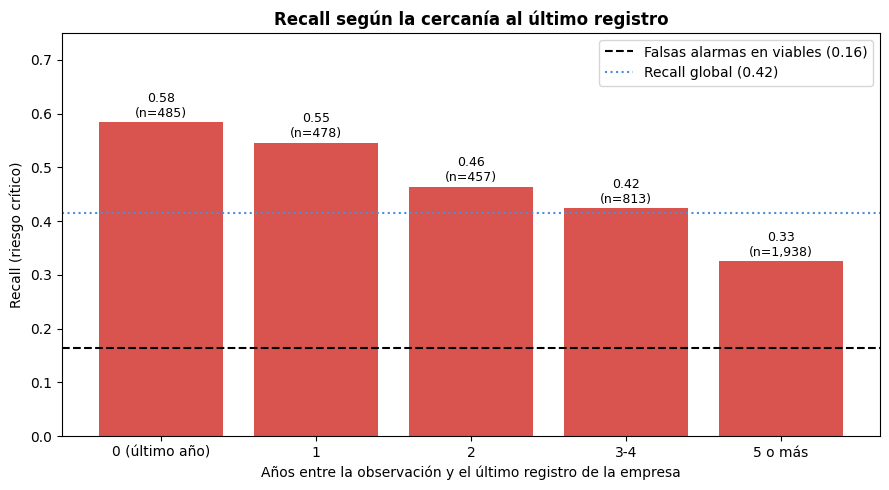

In [ ]:
falsas_alarmas = diag[diag['y'] == 0]['pred'].mean()
recall_global = diag[diag['y'] == 1]['pred'].mean()

fig, ax = plt.subplots(figsize=(9, 5))
barras = ax.bar(tabla_tramos.index.astype(str), tabla_tramos['recall'], color='#D9534F')
for b, v, n in zip(barras, tabla_tramos['recall'], tabla_tramos['observaciones']):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.01, f'{v:.2f}\n(n={n:,})', ha='center', fontsize=9)
ax.axhline(falsas_alarmas, color='black', linestyle='--', label=f'Falsas alarmas en viables ({falsas_alarmas:.2f})')
ax.axhline(recall_global, color='#4A90D9', linestyle=':', label=f'Recall global ({recall_global:.2f})')
ax.set_ylim(0, 0.75)
ax.set_xlabel('Años entre la observación y el último registro de la empresa')
ax.set_ylabel('Recall (riesgo crítico)')
ax.set_title('Recall según la cercanía al último registro', fontweight='bold')
ax.legend()
plt.tight_layout()
plt.show()

**Umbral, Tabla 11 y Figura 11**

Probabilidades fuera de pliegue: 5.5 min


,Umbral,Recall,Precisión,F1,% marcado como riesgo
0,0.3,0.740,0.105,0.184,46.749
1,0.4,0.578,0.126,0.207,30.405
2,0.5,0.415,0.152,0.223,18.079
3,0.6,0.261,0.183,0.215,9.450
4,0.7,0.126,0.219,0.160,3.815


Umbral elegido: 0.5


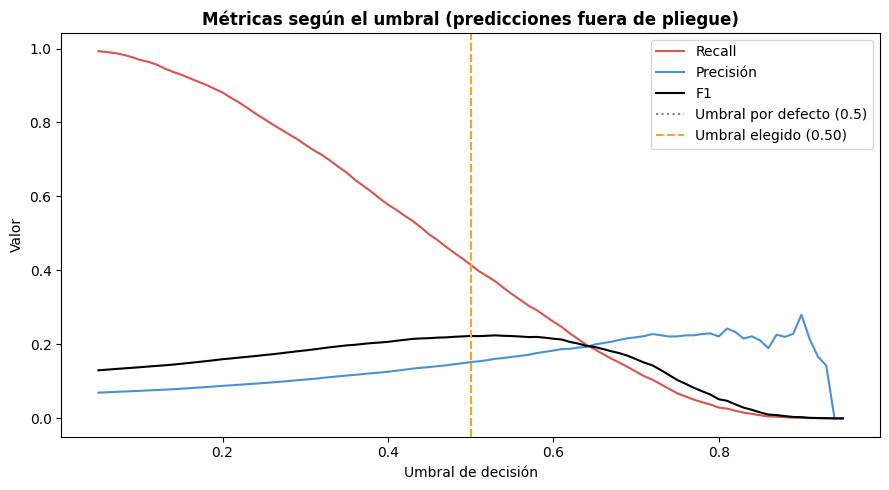

In [ ]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_score, recall_score, f1_score
import json, time

t0 = time.time()
proba_oof = cross_val_predict(modelo_final, X_train, y_train, groups=g_train,
                              cv=cv_interna, method='predict_proba', n_jobs=1)[:, 1]
print(f'Probabilidades fuera de pliegue: {(time.time() - t0) / 60:.1f} min')

grilla = np.round(np.arange(0.05, 0.96, 0.01), 2)
barrido = pd.DataFrame({
    'Umbral': grilla,
    'Recall': [recall_score(y_train, (proba_oof >= u).astype(int)) for u in grilla],
    'Precisión': [precision_score(y_train, (proba_oof >= u).astype(int), zero_division=0) for u in grilla],
    'F1': [f1_score(y_train, (proba_oof >= u).astype(int)) for u in grilla],
    '% marcado como riesgo': [(proba_oof >= u).mean() * 100 for u in grilla]
})

# Regla fijada ANTES de ver la prueba: maximizar F1 (RECALL_MINIMO = 0.0 desactiva la restricción)
RECALL_MINIMO = 0.40
cand = barrido[barrido['Recall'] >= RECALL_MINIMO]
if cand.empty:
    cand = barrido
UMBRAL_FINAL = float(cand.loc[cand['F1'].idxmax(), 'Umbral'])

mostrar = sorted(set([0.30, 0.40, 0.50, 0.60, 0.70, UMBRAL_FINAL]))
tabla_umbrales = barrido[barrido['Umbral'].isin(mostrar)].round(3).reset_index(drop=True)
display(tabla_umbrales)
print('Umbral elegido:', UMBRAL_FINAL)

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(barrido['Umbral'], barrido['Recall'], color='#D9534F', label='Recall')
ax.plot(barrido['Umbral'], barrido['Precisión'], color='#4A90D9', label='Precisión')
ax.plot(barrido['Umbral'], barrido['F1'], color='black', label='F1')
ax.axvline(0.5, color='gray', linestyle=':', label='Umbral por defecto (0.5)')
ax.axvline(UMBRAL_FINAL, color='#F5A623', linestyle='--', label=f'Umbral elegido ({UMBRAL_FINAL:.2f})')
ax.set_xlabel('Umbral de decisión')
ax.set_ylabel('Valor')
ax.set_title('Métricas según el umbral (predicciones fuera de pliegue)', fontweight='bold')
ax.legend()
plt.tight_layout()
plt.show()

# Se guarda junto al modelo (RF11)
ruta_meta = f'{RUTA_PROYECTO}/modelo_final_metadatos.json'
with open(ruta_meta, encoding='utf-8') as f:
    meta = json.load(f)
meta['umbral_decision'] = UMBRAL_FINAL
with open(ruta_meta, 'w', encoding='utf-8') as f:
    json.dump(meta, f, ensure_ascii=False, indent=2)

**Aplicacion de la prueba (Tabla 12)**

In [ ]:
import json
from sklearn.metrics import (precision_score, recall_score, f1_score,
                             average_precision_score, confusion_matrix)

# Conjunto de prueba y umbral: se leen de Drive para garantizar que son los fijados antes
prueba = pd.read_csv(f'{RUTA_PROYECTO}/dataset_prueba.csv')
X_test = prueba[VARIABLES_MODELO].copy()
y_test = prueba['riesgo_critico'].copy()
g_test = prueba['empresa'].copy()

with open(f'{RUTA_PROYECTO}/modelo_final_metadatos.json', encoding='utf-8') as f:
    UMBRAL_FINAL = json.load(f)['umbral_decision']
print('Umbral fijado en 5.1.4:', UMBRAL_FINAL)
print('Prueba:', X_test.shape, '| empresas:', g_test.nunique(), '| en riesgo:', g_test[y_test == 1].nunique())

# Única aplicación del modelo sobre la prueba
proba_test = modelo_final.predict_proba(X_test)[:, 1]
np.save(f'{RUTA_PROYECTO}/proba_prueba.npy', proba_test)   # la sección 6 reutiliza estas probabilidades

def metricas(u, etiqueta):
    p = (proba_test >= u).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, p).ravel()
    return {'Umbral': etiqueta, 'Recall': round(recall_score(y_test, p), 3),
            'Precisión': round(precision_score(y_test, p, zero_division=0), 3),
            'F1': round(f1_score(y_test, p), 3),
            'Riesgo detectado': tp, 'Riesgo no detectado': fn, 'Falsas alarmas': fp}

filas = [metricas(0.5, '0.50 (por defecto)')]
if abs(UMBRAL_FINAL - 0.5) > 1e-9:
    filas.append(metricas(UMBRAL_FINAL, f'{UMBRAL_FINAL:.2f} (elegido)'))
tabla_prueba = pd.DataFrame(filas).set_index('Umbral')
display(tabla_prueba)

print('PR-AUC en prueba:', round(average_precision_score(y_test, proba_test), 3),
      '| referencia (prevalencia):', round(y_test.mean(), 3))

# Intervalo de incertidumbre: remuestreo de empresas completas (500 repeticiones)
rng = np.random.default_rng(SEMILLA)
pred_u = (proba_test >= UMBRAL_FINAL).astype(int)
idx_por_empresa = pd.Series(np.arange(len(g_test))).groupby(g_test.values).apply(np.array)
empresas = idx_por_empresa.index.values
f1s, recs = [], []
for _ in range(500):
    muestra = rng.choice(empresas, size=len(empresas), replace=True)
    idx = np.concatenate([idx_por_empresa[e] for e in muestra])
    f1s.append(f1_score(y_test.values[idx], pred_u[idx], zero_division=0))
    recs.append(recall_score(y_test.values[idx], pred_u[idx]))
print('F1     IC 95 %:', np.round(np.percentile(f1s, [2.5, 97.5]), 3))
print('Recall IC 95 %:', np.round(np.percentile(recs, [2.5, 97.5]), 3))

Umbral fijado en 5.1.4: 0.5
Prueba: (15742, 17) | empresas: 1794 | en riesgo: 124


,Recall,Precisión,F1,Riesgo detectado,Riesgo no detectado,Falsas alarmas
Umbral,,,,,,
0.50 (por defecto),0.388,0.139,0.205,407,642,2516


PR-AUC en prueba: 0.135 | referencia (prevalencia): 0.067
F1     IC 95 %: [0.17  0.238]
Recall IC 95 %: [0.334 0.443]
